In [6]:
#historical flood-impact patterns using k means

import pandas as pd
import glob

matches = glob.glob(
    '/content/drive/MyDrive/FloodRelief_AI/data/district_population_exposure.csv',
    recursive=True
)

if not matches:
    print("Dataset not found in Google Drive.")
else:
    df = pd.read_csv(matches[0])
    print("Dataset loaded successfully!")
    print("Shape:", df.shape)
    display(df.head())


Dataset loaded successfully!
Shape: (732, 14)


,District,State,Population,Percent_Flooded_Area,Permanent_Water,Corrected_Percent_Flooded_Area,DFSI,Population_Exposure,Human_fatality,Human_injured,Casualties,Mean_Flood_Duration,DFSI_Source_Rows,State_Match_Method
0,Nicobars,Andaman & Nicobar,27340,0.090612,0.000000,0.090612,4.664727,25,0,0,0,NaN,1,Unique district-state match in DFSI
1,North & Middle Andaman,Andaman & Nicobar,101677,1.314817,0.000000,1.314817,7.462575,1337,0,0,0,1.0,1,Unique district-state match in DFSI
2,South Andaman,Andaman & Nicobar,257900,1.443452,0.000000,1.443452,8.360463,3723,1,0,1,2.0,1,Unique district-state match in DFSI
3,Anantapur,Andhra Pradesh,4537583,0.698642,0.216018,0.482624,15.320256,21899,118,1,119,10.0,1,Unique district-state match in DFSI
4,Chittoor,Andhra Pradesh,4580686,0.573483,0.068958,0.504525,14.968532,23111,124,0,124,8.0,1,Unique district-state match in DFSI


In [7]:

print("Casualties statistics:")
print(df['Casualties'].describe())

print("\nDistricts with zero casualties:")
print((df['Casualties'] == 0).sum())

print("\nAre casualties equal to fatalities + injuries?")
print(
    (
        df['Casualties'] ==
        df['Human_fatality'] + df['Human_injured']
    ).all()
)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Casualties statistics:
count     732.000000
mean      105.385246
std       171.907315
min         0.000000
25%        13.000000
50%        56.500000
75%       140.250000
max      1734.000000
Name: Casualties, dtype: float64

Districts with zero casualties:
36

Are casualties equal to fatalities + injuries?
True

Missing values:
DFSI                    1
Mean_Flood_Duration    11
dtype: int64


In [8]:

cluster_features = [
    'Corrected_Percent_Flooded_Area',
    'DFSI',
    'Mean_Flood_Duration',
    'Population_Exposure'
]

print(df[cluster_features].describe().round(2))

print("\nMissing values:")
print(df[cluster_features].isnull().sum())

print("\nFeature correlations:")
display(df[cluster_features].corr().round(2))


       Corrected_Percent_Flooded_Area    DFSI  Mean_Flood_Duration  \
count                          732.00  731.00               721.00   
mean                             2.71   13.54                10.82   
std                              3.81    2.93                 8.29   
min                              0.00    4.24                 1.00   
25%                              0.46   11.50                 5.00   
50%                              1.22   14.05                 7.00   
75%                              3.34   15.81                17.00   
max                             23.62   19.30                35.00   

       Population_Exposure  
count               732.00  
mean              65309.90  
std              141817.77  
min                   1.00  
25%                3136.25  
50%               13168.50  
75%               61752.00  
max             1292779.00  

Missing values:
Corrected_Percent_Flooded_Area     0
DFSI                               1
Mean_Flood_Durati

,Corrected_Percent_Flooded_Area,DFSI,Mean_Flood_Duration,Population_Exposure
Corrected_Percent_Flooded_Area,1.00,0.36,0.26,0.71
DFSI,0.36,1.00,0.36,0.44
Mean_Flood_Duration,0.26,0.36,1.00,0.29
Population_Exposure,0.71,0.44,0.29,1.00


In [9]:
#preprocessing

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

cluster_features = [
    'Corrected_Percent_Flooded_Area',
    'DFSI',
    'Mean_Flood_Duration'
]

X_cluster = df[cluster_features].copy()

# Fill missing values using median
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X_cluster)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Original shape:", X_cluster.shape)
print("Processed shape:", X_scaled.shape)
print("Missing values remaining:",
      pd.DataFrame(X_scaled).isnull().sum().sum())


Original shape: (732, 3)
Processed shape: (732, 3)
Missing values remaining: 0


K=2 | Inertia=1305.70 | Silhouette=0.4373
K=3 | Inertia=934.61 | Silhouette=0.4420
K=4 | Inertia=608.26 | Silhouette=0.4263
K=5 | Inertia=535.49 | Silhouette=0.4062
K=6 | Inertia=470.93 | Silhouette=0.3247
K=7 | Inertia=418.87 | Silhouette=0.3162
K=8 | Inertia=370.52 | Silhouette=0.3240


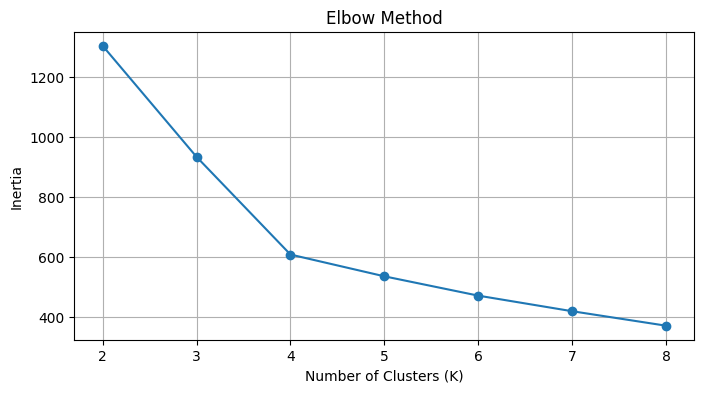

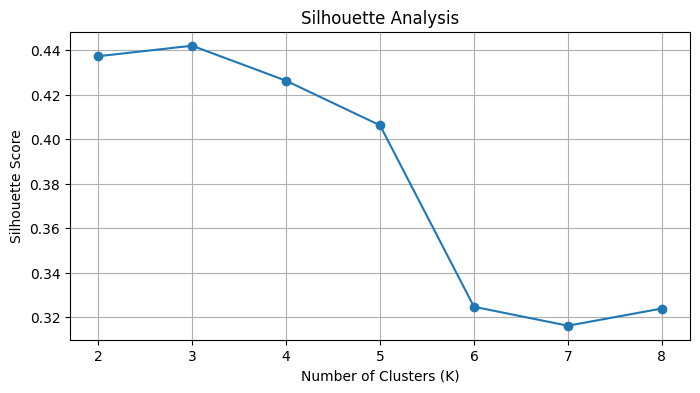

In [10]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

    print(
        f"K={k} | Inertia={model.inertia_:.2f} | "
        f"Silhouette={silhouette_scores[-1]:.4f}"
    )

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertias, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.grid(True)
plt.show()


In [11]:

from sklearn.cluster import KMeans

kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

df['Cluster'] = kmeans_model.fit_predict(X_scaled)

print("Districts per cluster:")
print(df['Cluster'].value_counts().sort_index())

print("\nFinal Silhouette Score:")
print(round(silhouette_score(X_scaled, df['Cluster']), 4))


Districts per cluster:
Cluster
0    465
1     81
2    186
Name: count, dtype: int64

Final Silhouette Score:
0.442


In [12]:

cluster_summary = df.groupby('Cluster').agg(
    Districts=('District', 'count'),
    Avg_Flooded_Area=('Corrected_Percent_Flooded_Area', 'mean'),
    Avg_DFSI=('DFSI', 'mean'),
    Avg_Flood_Duration=('Mean_Flood_Duration', 'mean'),
    Avg_Population_Exposure=('Population_Exposure', 'mean'),
    Total_Population_Exposure=('Population_Exposure', 'sum')
).round(2)

display(cluster_summary)


,Districts,Avg_Flooded_Area,Avg_DFSI,Avg_Flood_Duration,Avg_Population_Exposure,Total_Population_Exposure
Cluster,,,,,,
0,465,1.20,12.40,5.65,16322.77,7590087
1,81,11.75,16.23,14.44,322300.99,26106380
2,186,2.56,15.22,21.85,75862.27,14110383


In [13]:

cluster_names = {
    0: "Low Flood Impact",
    1: "High Flood Impact",
    2: "Long-Duration Flood Impact"
}

df['Vulnerability_Group'] = df['Cluster'].map(cluster_names)

display(df[
    ['State', 'District', 'Cluster',
     'Vulnerability_Group', 'Population_Exposure']
].head(10))


,State,District,Cluster,Vulnerability_Group,Population_Exposure
0,Andaman & Nicobar,Nicobars,0,Low Flood Impact,25
1,Andaman & Nicobar,North & Middle Andaman,0,Low Flood Impact,1337
2,Andaman & Nicobar,South Andaman,0,Low Flood Impact,3723
3,Andhra Pradesh,Anantapur,0,Low Flood Impact,21899
4,Andhra Pradesh,Chittoor,0,Low Flood Impact,23111
5,Andhra Pradesh,East Godavari,2,Long-Duration Flood Impact,206213
6,Andhra Pradesh,Guntur,1,High Flood Impact,496767
7,Andhra Pradesh,Krishna,0,Low Flood Impact,33725
8,Andhra Pradesh,Kurnool,0,Low Flood Impact,13351
9,Andhra Pradesh,Prakasam,0,Low Flood Impact,32789


In [15]:
#save the model
import joblib

model2_package = {
    'model': kmeans_model,
    'imputer': imputer,
    'scaler': scaler,
    'features': cluster_features,
    'cluster_names': cluster_names,
    'model_name': 'K-Means Clustering',
    'n_clusters': 3,
    'silhouette_score': 0.4420
}

joblib.dump(
    model2_package,
    'floodrelief_model2_complete.pkl'
)

print("Model 2 saved successfully!")


Model 2 saved successfully!


In [16]:
#Save the district dataset
df.to_csv(
    'district_clusters.csv',
    index=False
)

print("District dataset saved successfully!")
print("Shape:", df.shape)


District dataset saved successfully!
Shape: (732, 16)


In [17]:
#download
from google.colab import files

files.download('floodrelief_model2_complete.pkl')
files.download('district_clusters.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>